# Classifications MACHINE LEARNIG MODEL

![](https://www.studytrigger.com/wp-content/uploads/2023/04/Types-of-Leaning-in-Machine-Learning.png)

# SUPERVISED LEARNING
  # 1.REGRESSION
  - LINEAR MODEL  
      - LINEAR REGRESSION
  - NON LINEAR MODEL
    - SVM
    - DECISIION TREE
    - KNN
    - ENSEMBLE TECHNIQUES RANDOM FOREST
  
# 2. CLASSIFICATION
    - LINEAR MODEL  
      - LOGISTIC REGRESSION
  - NON LINEAR MODEL
    - SVM
    - DECISIION TREE
    - KNN
    - ENSEMBLE TECHNIQUES RANDOM FOREST

# Introduction to Classification - INSURANCE FRAUD CLAIM

# Predicting auto and insurance fraud in general:
is a contract, represented by a policy, in which an individual or entity receives financial protection or reimbursement against losses from an insurance company. The company pools clients' risks to make payments more affordable for the insured.

# Insurance Policy Components
When choosing a policy, it is important to understand how insurance works.

A firm understanding of these concepts goes a long way in helping you choose the policy that best suits your needs. For instance, whole life insurance may or may not be the right type of life insurance for you. There are three components of any type of insurance (premium, policy limit, and deductible) that are crucial.



1. Introduction to Logistic Regression
2. Linear Regesssion
3. Sigmoid Function
4. loss functions
5. Confusion Matrix
6. Classification Evaluation Metrics

https://www.kaggle.com/code/mohamedbakrey/make-a-prediction-for-insurance-claim-report

https://youtu.be/ntBa7YKc9XM?si=1V1RL0wCmxM_gjor  Regression price

https://youtu.be/OOLhKLXCJiU?si=dWxvFk82mVO8WxEP DBSCAN

> The goal of this note, Kuho Hwa, is to make a simplified and structured analysis to make an explanation of that dirty process called fraud and lack of it through analysis and the machine learning system.

# Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Read data

In [2]:
path =r'https://media.githubusercontent.com/media/shahil04/ds_materials/refs/heads/main/8.0_Machine%20Learning/class/Module%204.2%20insurance_claims_report.csv'
db = pd.read_csv(path)
# db=pd.read_csv('Module 4.2 insurance_claims_report.csv')
# https://github.com/shahil04/ds_materials/blob/main/8.0_Machine%20Learning/class/Module%204.2%20insurance_claims_report.csv
# https://www.google.com/url?q=https%3A%2F%2Fwww.kaggle.com%2Fcode%2Fmohamedbakrey%2Fmake-a-prediction-for-insurance-claim-report

In [3]:
db.head(10)

,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,...,witnesses,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,auto_year,fraud_reported
0,328,48,521585,17-10-2014,OH,250/500,1000,1406.91,0,466132,...,2,YES,71610,6510,13020,52080,Saab,92x,2004,Y
1,228,42,342868,27-06-2006,IN,250/500,2000,1197.22,5000000,468176,...,0,?,5070,780,780,3510,Mercedes,E400,2007,Y
2,134,18,687698,06-09-2000,OH,100/300,2000,1413.14,5000000,430632,...,3,NO,34650,7700,3850,23100,Dodge,RAM,2007,N
3,256,41,227811,25-05-1990,IL,250/500,2000,1415.74,6000000,608117,...,2,NO,63400,6340,6340,50720,Chevrolet,Tahoe,2014,Y
4,228,44,367455,06-06-2014,IL,500/1000,1000,1583.91,6000000,610706,...,1,NO,6500,1300,650,4550,Accura,RSX,2009,N
5,256,39,104594,12-10-2006,OH,250/500,1000,1351.10,0,478456,...,2,NO,64100,6410,6410,51280,Saab,95,2003,Y
6,137,34,413978,04-06-2000,IN,250/500,1000,1333.35,0,441716,...,0,?,78650,21450,7150,50050,Nissan,Pathfinder,2012,N
7,165,37,429027,03-02-1990,IL,100/300,1000,1137.03,0,603195,...,2,YES,51590,9380,9380,32830,Audi,A5,2015,N
8,27,33,485665,05-02-1997,IL,100/300,500,1442.99,0,601734,...,1,YES,27700,2770,2770,22160,Toyota,Camry,2012,N
9,212,42,636550,25-07-2011,IL,100/300,500,1315.68,0,600983,...,1,?,42300,4700,4700,32900,Saab,92x,1996,N


In [4]:
db.columns

Index(['months_as_customer', 'age', 'policy_number', 'policy_bind_date',
       'policy_state', 'policy_csl', 'policy_deductable',
       'policy_annual_premium', 'umbrella_limit', 'insured_zip', 'insured_sex',
       'insured_education_level', 'insured_occupation', 'insured_hobbies',
       'insured_relationship', 'capital-gains', 'capital-loss',
       'incident_date', 'incident_type', 'collision_type', 'incident_severity',
       'authorities_contacted', 'incident_state', 'incident_city',
       'incident_location', 'incident_hour_of_the_day',
       'number_of_vehicles_involved', 'property_damage', 'bodily_injuries',
       'witnesses', 'police_report_available', 'total_claim_amount',
       'injury_claim', 'property_claim', 'vehicle_claim', 'auto_make',
       'auto_model', 'auto_year', 'fraud_reported'],
      dtype='object')

In [5]:
db.shape

(1000, 39)

In [6]:
pd.set_option('display.max_columns', 50) # to show all columns in the output
db.head()

,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,insured_sex,insured_education_level,insured_occupation,insured_hobbies,insured_relationship,capital-gains,capital-loss,incident_date,incident_type,collision_type,incident_severity,authorities_contacted,incident_state,incident_city,incident_location,incident_hour_of_the_day,number_of_vehicles_involved,property_damage,bodily_injuries,witnesses,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,auto_year,fraud_reported
0,328,48,521585,17-10-2014,OH,250/500,1000,1406.91,0,466132,MALE,MD,craft-repair,sleeping,husband,53300,0,25-01-2015,Single Vehicle Collision,Side Collision,Major Damage,Police,SC,Columbus,9935 4th Drive,5,1,YES,1,2,YES,71610,6510,13020,52080,Saab,92x,2004,Y
1,228,42,342868,27-06-2006,IN,250/500,2000,1197.22,5000000,468176,MALE,MD,machine-op-inspct,reading,other-relative,0,0,21-01-2015,Vehicle Theft,?,Minor Damage,Police,VA,Riverwood,6608 MLK Hwy,8,1,?,0,0,?,5070,780,780,3510,Mercedes,E400,2007,Y
2,134,18,687698,06-09-2000,OH,100/300,2000,1413.14,5000000,430632,FEMALE,PhD,sales,board-games,own-child,35100,0,22-02-2015,Multi-vehicle Collision,Rear Collision,Minor Damage,Police,NY,Columbus,7121 Francis Lane,7,3,NO,2,3,NO,34650,7700,3850,23100,Dodge,RAM,2007,N
3,256,41,227811,25-05-1990,IL,250/500,2000,1415.74,6000000,608117,FEMALE,PhD,armed-forces,board-games,unmarried,48900,-62400,10-01-2015,Single Vehicle Collision,Front Collision,Major Damage,Police,OH,Arlington,6956 Maple Drive,5,1,?,1,2,NO,63400,6340,6340,50720,Chevrolet,Tahoe,2014,Y
4,228,44,367455,06-06-2014,IL,500/1000,1000,1583.91,6000000,610706,MALE,Associate,sales,board-games,unmarried,66000,-46000,17-02-2015,Vehicle Theft,?,Minor Damage,NaN,NY,Arlington,3041 3rd Ave,20,1,NO,0,1,NO,6500,1300,650,4550,Accura,RSX,2009,N


In [7]:
db.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 39 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   months_as_customer           1000 non-null   int64  
 1   age                          1000 non-null   int64  
 2   policy_number                1000 non-null   int64  
 3   policy_bind_date             1000 non-null   object 
 4   policy_state                 1000 non-null   object 
 5   policy_csl                   1000 non-null   object 
 6   policy_deductable            1000 non-null   int64  
 7   policy_annual_premium        1000 non-null   float64
 8   umbrella_limit               1000 non-null   int64  
 9   insured_zip                  1000 non-null   int64  
 10  insured_sex                  1000 non-null   object 
 11  insured_education_level      1000 non-null   object 
 12  insured_occupation           1000 non-null   object 
 13  insured_hobbies    

In [8]:
db.isnull().sum()

months_as_customer              0
age                             0
policy_number                   0
policy_bind_date                0
policy_state                    0
policy_csl                      0
policy_deductable               0
policy_annual_premium           0
umbrella_limit                  0
insured_zip                     0
insured_sex                     0
insured_education_level         0
insured_occupation              0
insured_hobbies                 0
insured_relationship            0
capital-gains                   0
capital-loss                    0
incident_date                   0
incident_type                   0
collision_type                  0
incident_severity               0
authorities_contacted          91
incident_state                  0
incident_city                   0
incident_location               0
incident_hour_of_the_day        0
number_of_vehicles_involved     0
property_damage                 0
bodily_injuries                 0
witnesses     

In [9]:
db["authorities_contacted"].mode() #replace with mode

0    Police
Name: authorities_contacted, dtype: object

In [10]:
db["authorities_contacted"].value_counts()

authorities_contacted
Police       292
Fire         223
Other        198
Ambulance    196
Name: count, dtype: int64

In [12]:
db["authorities_contacted"].fillna(db["authorities_contacted"].mode()[0], inplace=True)

In [13]:
db.columns

Index(['months_as_customer', 'age', 'policy_number', 'policy_bind_date',
       'policy_state', 'policy_csl', 'policy_deductable',
       'policy_annual_premium', 'umbrella_limit', 'insured_zip', 'insured_sex',
       'insured_education_level', 'insured_occupation', 'insured_hobbies',
       'insured_relationship', 'capital-gains', 'capital-loss',
       'incident_date', 'incident_type', 'collision_type', 'incident_severity',
       'authorities_contacted', 'incident_state', 'incident_city',
       'incident_location', 'incident_hour_of_the_day',
       'number_of_vehicles_involved', 'property_damage', 'bodily_injuries',
       'witnesses', 'police_report_available', 'total_claim_amount',
       'injury_claim', 'property_claim', 'vehicle_claim', 'auto_make',
       'auto_model', 'auto_year', 'fraud_reported'],
      dtype='object')

In [14]:
db.isnull().sum()

months_as_customer             0
age                            0
policy_number                  0
policy_bind_date               0
policy_state                   0
policy_csl                     0
policy_deductable              0
policy_annual_premium          0
umbrella_limit                 0
insured_zip                    0
insured_sex                    0
insured_education_level        0
insured_occupation             0
insured_hobbies                0
insured_relationship           0
capital-gains                  0
capital-loss                   0
incident_date                  0
incident_type                  0
collision_type                 0
incident_severity              0
authorities_contacted          0
incident_state                 0
incident_city                  0
incident_location              0
incident_hour_of_the_day       0
number_of_vehicles_involved    0
property_damage                0
bodily_injuries                0
witnesses                      0
police_rep

## Visalizations for data for analysis

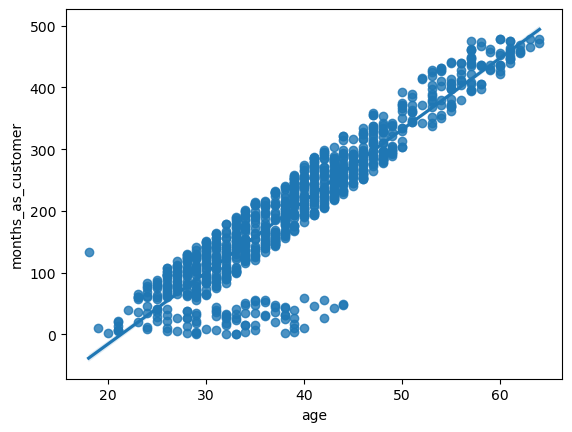

In [15]:
# check the realtionship beween age and customers years
ax=sns.regplot(x='age',y='months_as_customer',data=db)

- Before apply models , we need to check the data quality and data preprocessing.
    - We need to check the data for missing values, outliers, and data types.
    - We need to handle missing values by either removing them or imputing them with a suitable
    method.
    - We need to transform the data into a suitable format for modeling, such as scaling or encoding
    categorical variables.
    - We need to split the data into training and testing sets to evaluate the model's performance.

# Let's apply our classification models one by one:
1) Logistic Regression:

In [16]:
# check how many columns --> so i decide which columns are important
db.columns

Index(['months_as_customer', 'age', 'policy_number', 'policy_bind_date',
       'policy_state', 'policy_csl', 'policy_deductable',
       'policy_annual_premium', 'umbrella_limit', 'insured_zip', 'insured_sex',
       'insured_education_level', 'insured_occupation', 'insured_hobbies',
       'insured_relationship', 'capital-gains', 'capital-loss',
       'incident_date', 'incident_type', 'collision_type', 'incident_severity',
       'authorities_contacted', 'incident_state', 'incident_city',
       'incident_location', 'incident_hour_of_the_day',
       'number_of_vehicles_involved', 'property_damage', 'bodily_injuries',
       'witnesses', 'police_report_available', 'total_claim_amount',
       'injury_claim', 'property_claim', 'vehicle_claim', 'auto_make',
       'auto_model', 'auto_year', 'fraud_reported'],
      dtype='object')

In [17]:
len(db.columns)
db.shape

(1000, 39)

In [18]:
db.dtypes

months_as_customer               int64
age                              int64
policy_number                    int64
policy_bind_date                object
policy_state                    object
policy_csl                      object
policy_deductable                int64
policy_annual_premium          float64
umbrella_limit                   int64
insured_zip                      int64
insured_sex                     object
insured_education_level         object
insured_occupation              object
insured_hobbies                 object
insured_relationship            object
capital-gains                    int64
capital-loss                     int64
incident_date                   object
incident_type                   object
collision_type                  object
incident_severity               object
authorities_contacted           object
incident_state                  object
incident_city                   object
incident_location               object
incident_hour_of_the_day 

In [19]:
# if use only numerical columns for training
X = db[["months_as_customer","age","policy_annual_premium","auto_year" ,"umbrella_limit"]]

y = db['fraud_reported']
#  if you are using all columns  do EDA or preprocessing

In [20]:
X.corr()

,months_as_customer,age,policy_annual_premium,auto_year,umbrella_limit
months_as_customer,1.000000,0.920958,0.005018,-0.000292,0.015498
age,0.920958,1.000000,0.013603,0.000972,0.016049
policy_annual_premium,0.005018,0.013603,1.000000,-0.049226,-0.006247
auto_year,-0.000292,0.000972,-0.049226,1.000000,0.009893
umbrella_limit,0.015498,0.016049,-0.006247,0.009893,1.000000


In [22]:
X

,months_as_customer,age,policy_annual_premium,auto_year,umbrella_limit
0,328,48,1406.91,2004,0
1,228,42,1197.22,2007,5000000
2,134,18,1413.14,2007,5000000
3,256,41,1415.74,2014,6000000
4,228,44,1583.91,2009,6000000
...,...,...,...,...,...
995,3,38,1310.80,2006,0
996,285,41,1436.79,2015,0
997,130,34,1383.49,1996,3000000
998,458,62,1356.92,1998,5000000


In [23]:
y

0      Y
1      Y
2      N
3      Y
4      N
      ..
995    N
996    N
997    N
998    N
999    N
Name: fraud_reported, Length: 1000, dtype: object

In [24]:
# import methods for train test split
from sklearn.model_selection import train_test_split

In [25]:
#  split the data into training and tsting
# split the data into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=12)

In [26]:
X_train.shape

(700, 5)

In [27]:
# model load
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [28]:
pipe = make_pipeline(StandardScaler(), LogisticRegression())
pipe.fit(X_train, y_train)  # apply scaling on training data

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression())])

In [29]:
pipe.predict_proba(X_test) # to get the probabilities of each class

array([[0.77415804, 0.22584196],
       [0.75849877, 0.24150123],
       [0.75273559, 0.24726441],
       [0.77361992, 0.22638008],
       [0.73746557, 0.26253443],
       [0.79613674, 0.20386326],
       [0.76074319, 0.23925681],
       [0.75711236, 0.24288764],
       [0.77059495, 0.22940505],
       [0.7811496 , 0.2188504 ],
       [0.76773806, 0.23226194],
       [0.7554371 , 0.2445629 ],
       [0.77837092, 0.22162908],
       [0.77125836, 0.22874164],
       [0.71695755, 0.28304245],
       [0.76696042, 0.23303958],
       [0.76232582, 0.23767418],
       [0.71709543, 0.28290457],
       [0.76265725, 0.23734275],
       [0.75265879, 0.24734121],
       [0.76041419, 0.23958581],
       [0.71763292, 0.28236708],
       [0.77322986, 0.22677014],
       [0.76709733, 0.23290267],
       [0.78005842, 0.21994158],
       [0.76445607, 0.23554393],
       [0.77107129, 0.22892871],
       [0.76196993, 0.23803007],
       [0.78022291, 0.21977709],
       [0.75653446, 0.24346554],
       [0.

In [30]:
y_pred = pipe.predict(X_test)
y_pred

array(['N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N',
       'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N',
       'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N',
       'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N',
       'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N',
       'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N',
       'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N',
       'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N',
       'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N',
       'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N',
       'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N',
       'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N',
       'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N',
       'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N

In [31]:
# check the accuracy  of model
from sklearn.metrics import accuracy_score
print('Accuracy: {}'.format(accuracy_score(y_test, y_pred)))

Accuracy: 0.7466666666666667


In [32]:
from sklearn.metrics import classification_report,confusion_matrix

In [34]:
print(confusion_matrix(y_test, y_pred))

[[224   0]
 [ 76   0]]


In [35]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           N       0.75      1.00      0.85       224
           Y       0.00      0.00      0.00        76

    accuracy                           0.75       300
   macro avg       0.37      0.50      0.43       300
weighted avg       0.56      0.75      0.64       300



c:\Users\hp\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\hp\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\hp\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


![](https://cdn.prod.website-files.com/660ef16a9e0687d9cc27474a/662c42677529a0f4e97e4f9c_644aec2628bc14d83ca873a2_class_guide_cm10.png)
![](https://almablog-media.s3.ap-south-1.amazonaws.com/image_14_4f4fc2cf7d.png)

![](https://cdn.analyticsvidhya.com/wp-content/uploads/2024/07/sdfgvb-01-1-scaled.webp)

![](https://i.ytimg.com/vi/FvIjv9-Xx1o/maxresdefault.jpg)

![](https://framerusercontent.com/images/1NNVbuTCbyaX2tWbtyErU4vFpOk.webp?width=1531&height=566)


Here’s the step-by-step from your confusion matrix
(rows = actual \[N, Y], cols = predicted \[N, Y]):

```
[[220, 0],
 [ 80, 0]]
```

* For class **Y** as the “positive” class:

  * TP = 0  (actual Y, predicted Y)
  * FP = 0  (actual N, predicted Y)
  * FN = 80 (actual Y, predicted N)
  * TN = 220 (actual N, predicted N)

### Per-class metrics

**Class Y**

* Precision\_Y = TP/(TP+FP) = 0/(0+0) → undefined → sklearn reports **0.00**
* Recall\_Y = TP/(TP+FN) = 0/(0+80) = **0.00**
* F1\_Y = 0 (since precision or recall is 0)

**Class N** (one-vs-rest view, treat N as “positive”)

* TP\_N = 220, FP\_N = 80, FN\_N = 0, TN\_N = 0
* Precision\_N = 220/(220+80) = **0.7333 ≈ 0.73**
* Recall\_N = 220/(220+0) = **1.00**
* F1\_N = 2\*(0.7333\*1)/(0.7333+1) = **0.846 ≈ 0.85**

### Overall metrics

* **Accuracy** = (TP+TN)/(total) = (0+220)/300 = **0.733 ≈ 0.73**

* **Macro avg** (simple mean of classes)

  * Precision = (0.7333 + 0)/2 = **0.3667 ≈ 0.37**
  * Recall = (1.0 + 0)/2 = **0.50**
  * F1 = (0.846 + 0)/2 = **0.423 ≈ 0.42**

* **Weighted avg** (weighted by support: 220 for N, 80 for Y)

  * Precision = (0.7333*220 + 0*80)/300 = **0.537 ≈ 0.54**
  * Recall = (1.0*220 + 0*80)/300 = **0.733 ≈ 0.73**
  * F1 = (0.846*220 + 0*80)/300 = **0.620 ≈ 0.62**

That matches your `classification_report`. The key confusion point: for class **Y** there are **no predicted positives**, so precision is 0/0 (undefined) and sklearn returns **0.00**.


In [36]:
import pickle
filename = 'logistic_model.pkl'

pickle.dump(pipe, open(filename, 'wb'))

In [38]:
pipe = make_pipeline(StandardScaler(), LogisticRegression(penalty="l2",solver="saga",C=.20))

pipe.fit(X_train, y_train)  # apply scaling on training data

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(C=0.2, solver='saga'))])

In [39]:
y_pred = pipe.predict(X_test)

print('Accuracy: {}'.format(accuracy_score(y_test, y_pred)))

Accuracy: 0.7466666666666667


## Stream_lit code

In [ ]:
import streamlit as st
import pandas as pd
import pickle

# Load the trained model
filename = 'logistic_model.pkl'
loaded_model = pickle.load(open(filename, 'rb'))

st.title("Insurance Claim Fraud Prediction")

st.write("""
This app predicts whether an insurance claim is fraudulent based on several factors.
""")

# Define input fields for numerical features
months_as_customer      = st.number_input('Months as Customer', min_value=0, max_value=500, value=100)
age                     = st.number_input('Age', min_value=18, max_value=100, value=30)
policy_annual_premium   = st.number_input('Policy Annual Premium', min_value=0.0, max_value=2500.0, value=1000.0)
auto_year               = st.number_input('Auto Year', min_value=1980, max_value=2023, value=2010)
umbrella_limit          = st.number_input('Umbrella Limit', min_value=-10000000, max_value=10000000, value=0)


# Create a button to make a prediction
if st.button('Predict Fraud'):
    # Create a DataFrame from the input values
    input_data = pd.DataFrame({
        'months_as_customer': [months_as_customer],
        'age': [age],
        'policy_annual_premium': [policy_annual_premium],
        'auto_year': [auto_year],
        'umbrella_limit': [umbrella_limit]
      })

    # Select only the numerical columns used for prediction based on the original code
    numerical_cols_for_prediction = ['months_as_customer', 'age', 'policy_annual_premium', 'auto_year', 'umbrella_limit']
    input_data_for_prediction = input_data[numerical_cols_for_prediction]

    # Make the prediction
    prediction = loaded_model.predict(input_data_for_prediction)

    # Display the prediction
    if prediction[0] == 'Y':
        st.write("Prediction: Fraud Reported (Y)")
    else:
        st.write("Prediction: No Fraud Reported (N)")




- Underfitting and Overfitting
- bias variance
- bias -variance tradeoff
- Regularization
- Cross Validation

### 🧠 **1. Underfitting**

**Definition:**
Underfitting happens when a model is **too simple** to capture the underlying patterns in the data.

**Example:**
Trying to fit a straight line (linear regression) to data that actually follows a curve (nonlinear relationship).

**Symptoms:**

* High training error
* High test error
* Model fails to capture important trends in the data

**Causes:**

* Model is not complex enough (e.g., using linear regression for complex data)
* Too few features
* Too much regularization (penalizing the model excessively)

**Solutions:**

* Use a more complex model
* Add more relevant features
* Reduce regularization
* Train longer or tune hyperparameters

---

### 🎯 **2. Overfitting**

**Definition:**
Overfitting happens when a model is **too complex** and learns **noise or random fluctuations** in the training data instead of the true underlying pattern.

**Example:**
A decision tree that perfectly classifies training data but performs poorly on new (test) data.

**Symptoms:**

* Very low training error
* High test error
* Model performs well on training data but poorly on unseen data

**Causes:**

* Model is too complex (too many parameters)
* Too little training data
* Noisy data
* Lack of regularization

**Solutions:**

* Use a simpler model
* Add more training data
* Use regularization (L1, L2, dropout, etc.)
* Use cross-validation
* Apply data augmentation (for images, text, etc.)

---

### 📊 **Visual Summary**

| Aspect           | Underfitting        | Overfitting                       |
| ---------------- | ------------------- | --------------------------------- |
| Model complexity | Too simple          | Too complex                       |
| Training error   | High                | Very low                          |
| Test error       | High                | High                              |
| Generalization   | Poor                | Poor                              |
| Solution         | Increase complexity | Decrease complexity or regularize |

---


https://www.geeksforgeeks.org/machine-learning/underfitting-and-overfitting-in-machine-learning/

![](https://www.mathworks.com/discovery/overfitting/_jcr_content/mainParsys/image.adapt.full.medium.svg/1746469504474.svg)

https://medium.com/@sharvenrane7/popular-regression-models-in-machine-learning-449ab77c7ba1

![](https://miro.medium.com/v2/resize:fit:720/format:webp/1*IzhAVzMGn83UN5-vozS7jw.png)

## Extra Models  implemetations in upcoming



In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

df = pd.read_csv("Module 4.2 insurance_claims_report.csv")
# Models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

# Features and target
X = df[["months_as_customer", "age", "policy_annual_premium", "auto_year", "umbrella_limit"]]
y = df["fraud_reported"]

# Encode target variable
le = LabelEncoder()
y_encoded = le.fit_transform(y)  # Y -> 1, N -> 0

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.3, random_state=42)

# Models dictionary
models = {
    "Logistic Regression": LogisticRegression(),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=3),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "Gradient Boosting": GradientBoostingClassifier(),
    "Support Vector Machine": SVC(),
    "Naive Bayes": GaussianNB(),
    "Neural Network (MLP)": MLPClassifier(max_iter=500)
}

# Train & evaluate all models
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    acc = accuracy_score(y_test, predictions)
    print(f"{name}:\nAccuracy = {acc:.2f}")
    print("=======================")